# **Nama: Andika Dinata**
# **NIM: 123140096**

# **1. Single Variable Linear Regression**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import random

Penjelasan:
Melakukan import library yang dibutuhkan

In [ ]:
np.random.seed(42)

Penjelasan:
Seed ditetapkan agar hasil setiap run konsisten.

## **1.1. Data Generation**

In [ ]:
num_samples = 500

# Pendefinisian fungsi yang sebenarnya (fungsi target) y = 4x - 1
true_w = np.array([4.0])
true_b = np.array([-1.0])

# Menghasilkan data input (x-axis)
features = np.random.randn(num_samples)

# Menghasilkan data output (y-axis)
# Catatan: untuk kondisi multivariate -> torch.matmul(features, true_w) + true_b
labels = features * true_w + true_b

# Menambahkan noise pada sebaran data yang ada
labels += (np.random.randint(low=1, high=3, size=num_samples) * np.random.randn(num_samples))

Penjelasan:
Medefinisikan fungsi yang ingin diaproksimasi oleh machine learning (target). Melakukan generate sampel data 500 buah yang sebarannya random tapi linear dengan fungsi target.

In [ ]:
# Eksplorasi Tambahan: memeriksa bentuk dan statistik data yang dihasilkan
print("Shape features :", features.shape)
print("Shape labels   :", labels.shape)
print(f"Mean / Std features : {features.mean():.3f} / {features.std():.3f}")
print(f"Min  / Max labels   : {labels.min():.3f} / {labels.max():.3f}")

# Noise sebenarnya = label yang diamati dikurangi label tanpa noise
noise = labels - (features * true_w + true_b)
print(f"Std noise (teori sekitar 1.58): {noise.std():.3f}")

Shape features : (500,)
Shape labels   : (500,)
Mean / Std features : 0.007 / 0.980
Min  / Max labels   : -14.145 / 14.630
Std noise (teori sekitar 1.58): 1.558


Penjelasan:
Memeriksa data yang dihasilkan sebelumnya

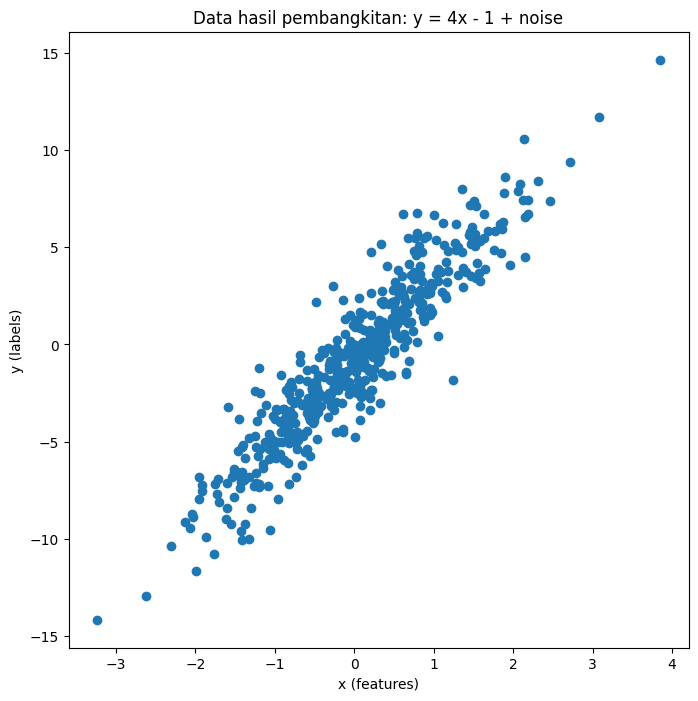

In [ ]:
# Visualisasi data
plt.figure(figsize=(8, 8))
plt.scatter(features, labels)
plt.xlabel('x (features)')
plt.ylabel('y (labels)')
plt.title('Data hasil pembangkitan: y = 4x - 1 + noise')
plt.show()

Penjelasan:
Memvisualisasikan data yang dihasilkan sebelumnya. Terlihat bahwa datanya linear dari kiri bawah ke kanan atas.

## **1.2. Data Preparation**

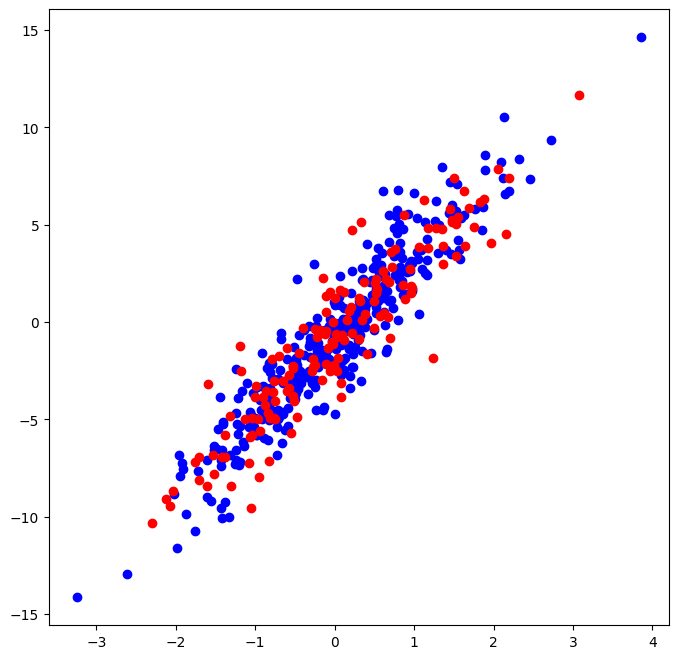

In [ ]:
train_size = 0.7
num_train = int(num_samples * train_size)

# Pembagian data ke training dan testing data
x_train = features[0:num_train]
y_train = labels[0:num_train]
x_test = features[num_train:num_samples]
y_test = labels[num_train:num_samples]

# Visualisasi Data
plt.figure(figsize=(8, 8))
plt.scatter(x_train, y_train, c='Blue')
plt.scatter(x_test, y_test, c='Red')
plt.show()

Penjelasan:
Membagi data training dan data testing.
70% untuk training, dan 30% untuk testing.

Serta melakukan visualisasi dari kedua data tersebut

In [ ]:
# Eksplorasi Tambahan: memeriksa ukuran masing-masing subset
print("Jumlah data latih :", len(x_train))
print("Jumlah data uji   :", len(x_test))

Jumlah data latih : 350
Jumlah data uji   : 150


## **1.3. Least Square Estimators**

In [ ]:
# 1. Menghitung nilai rata-rata (mean) dari x_train dan y_train
x_mean = np.mean(x_train)
y_mean = np.mean(y_train)

# 2. Menghitung gradient (b1) menggunakan rumus turunan Least Square
numerator = np.sum((x_train - x_mean) * (y_train - y_mean))
denominator = np.sum((x_train - x_mean) ** 2)
b1_hat = numerator / denominator

# 3. Menghitung intercept (b0)
b0_hat = y_mean - (b1_hat * x_mean)

# Evaluasi menggunakan Determination Coefficient (R2). Nilai evaluasi ini berbanding
# terbalik dengan SSR (Sum Square Residual) yang mana semakin besar nilai R2
# (mendekati nilai 1) maka semakin kecil nilai SSR-nya (mendekati nilai 0)
# R2 = 1 - (Sum Square Residual / Total Sum of Squares)
y_train_pred = b0_hat + b1_hat * x_train
ss_res = np.sum((y_train - y_train_pred) ** 2)
ss_tot = np.sum((y_train - y_mean) ** 2)
r_sq = 1 - (ss_res / ss_tot)

print('Coefficient of determination (R2):', r_sq)

# Menampilkan nilai b0 dan b1 yang dihasilkan dari perhitungan LSE
print('Intercept (b0):', b0_hat)
print('Gradient (b1):', b1_hat)

Coefficient of determination (R2): 0.8701258868759243
Intercept (b0): -0.8013782342083369
Gradient (b1): 4.114638230554753


Penjelasan:
Kode ini menerjemahkan rumus LSE langsung di numpy tanpa library machine learning

Melihat hasil b0 dan b1 yang dihasilkan dari perhitungan LSE. hasilnya mirip seperti fungsi target yang ingin kita approksimasi

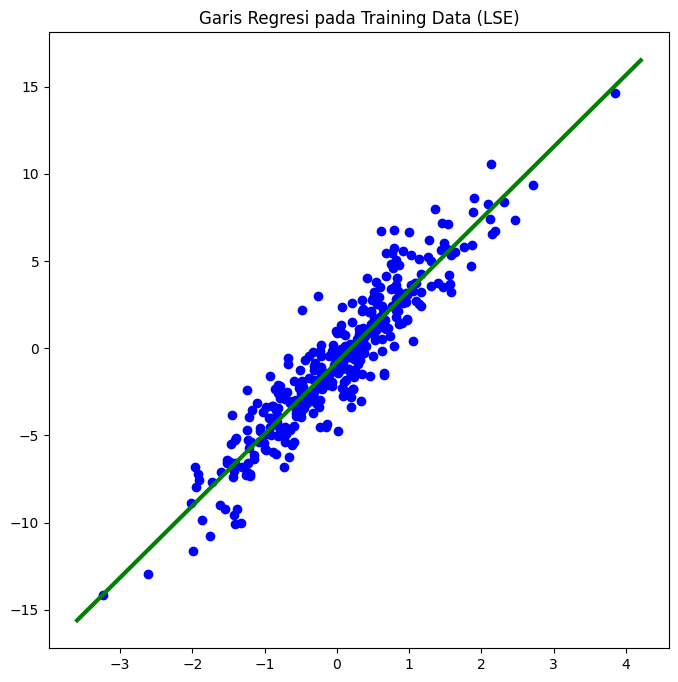

In [ ]:
# Menampilkan garis dari persamaan regresi linear terhadap training data
plt.figure(figsize=(8, 8))
plt.scatter(x_train, y_train, c='Blue')
axes = plt.gca()
x_vals = np.array(axes.get_xlim())

# Menggunakan b0_hat dan b1_hat dari kalkulasi manual
y_vals = b0_hat + b1_hat * x_vals
plt.plot(x_vals, y_vals, '-', c='Green', linewidth=3)
plt.title("Garis Regresi pada Training Data (LSE)")
plt.show()

Penjelasan:
Menampilkan B0 dan B1 dari perhitungan LSE

In [ ]:
# Eksplorasi Tambahan 1: verifikasi hasil LSE manual dengan np.polyfit
b1_np, b0_np = np.polyfit(x_train, y_train, deg=1)

print(f"{'Parameter':<12}{'Sebenarnya':>12}{'LSE manual':>14}{'np.polyfit':>14}")
print(f"{'b0':<12}{true_b[0]:>12.4f}{b0_hat:>14.4f}{b0_np:>14.4f}")
print(f"{'b1':<12}{true_w[0]:>12.4f}{b1_hat:>14.4f}{b1_np:>14.4f}")
print("\nHasil manual sama dengan polyfit?", np.allclose([b0_hat, b1_hat], [b0_np, b1_np]))

Parameter     Sebenarnya    LSE manual    np.polyfit
b0               -1.0000       -0.8014       -0.8014
b1                4.0000        4.1146        4.1146

Hasil manual sama dengan polyfit? True


Penjelasan:
Hasil dari LSE Manual dan NP Polyfit sama, mungkin karena rumus dibaliknya juga mekanismenya sama.

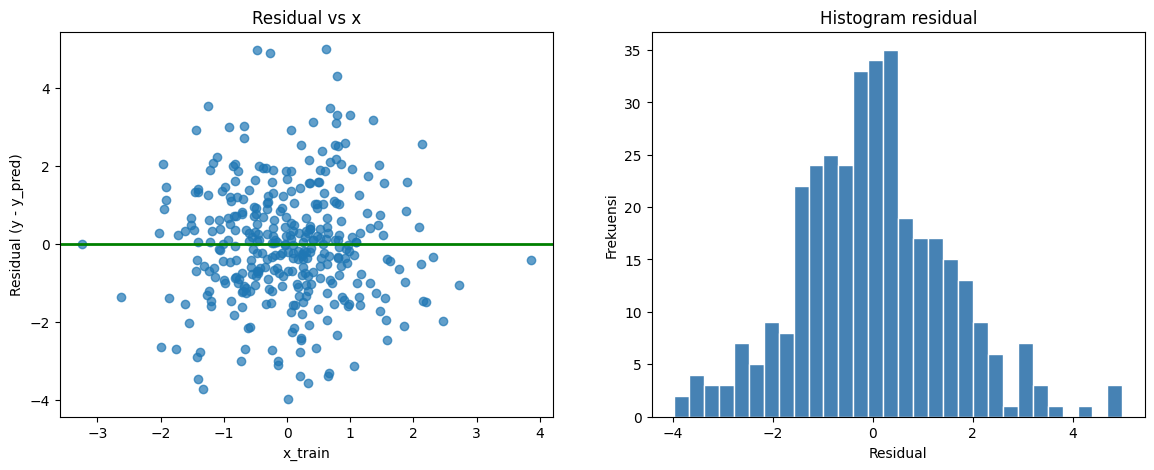

Rata-rata residual: 0.000000


In [ ]:
# Eksplorasi Tambahan 2: analisis residual pada data latih
residual = y_train - y_train_pred

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(x_train, residual, alpha=0.7)
ax[0].axhline(0, color='green', linewidth=2)
ax[0].set_xlabel('x_train')
ax[0].set_ylabel('Residual (y - y_pred)')
ax[0].set_title('Residual vs x')

ax[1].hist(residual, bins=30, color='steelblue', edgecolor='white')
ax[1].set_xlabel('Residual')
ax[1].set_ylabel('Frekuensi')
ax[1].set_title('Histogram residual')

plt.show()
print(f"Rata-rata residual: {residual.mean():.6f}")

Penjelasan:
Residual adalah selisih antara nilai sebenarnya dan prediksi.

Model linier yang cocok akan menghasilkan residual yang tersebar acak di sekitar 0 tanpa pola melengkung atau melebar (grafik kiri), dan berbentuk lonceng yang berpusat di 0 (histogram kanan).

Rata-rata residual pada data latih selalu bernilai hampir tepat 0.
Histogram sedikit lebih "gemuk" di ekor dibanding lonceng normal murni.

## **1.4. Testing Using Estimated Regression Parameters**

In [ ]:
# Menghitung nilai prediksi dan error (MSE) dari model terhadap testing set
y_test_pred = b0_hat + b1_hat * x_test
mse_test = np.mean((y_test_pred - y_test) ** 2)
print('Mean Squared Error (MSE) pada Testing Data: %.2f' % mse_test)

Mean Squared Error (MSE) pada Testing Data: 2.75


Penjelasan:
Menghitung nilai prediksi dan error dari model sebelumnya ke dataset testing.

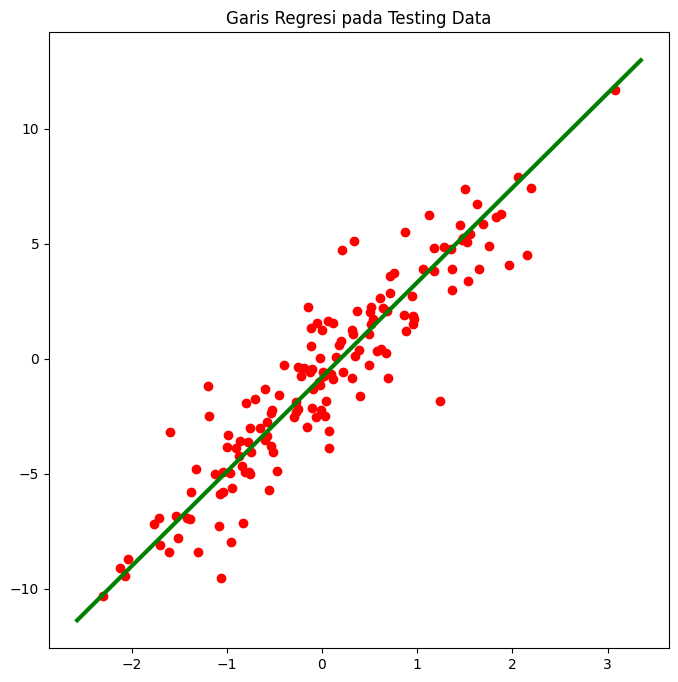

In [ ]:
# Menampilkan garis dari persamaan regresi linear terhadap testing data
plt.figure(figsize=(8, 8))
plt.scatter(x_test, y_test, c='Red')
axes = plt.gca()
x_vals = np.array(axes.get_xlim())
y_vals = b0_hat + b1_hat * x_vals
plt.plot(x_vals, y_vals, '-', c='Green', linewidth=3)
plt.title("Garis Regresi pada Testing Data")
plt.show()

Penjelasan:
Melakukan visualisasi model sebelumnya terhadap dataset testing. Hasilnya lurus tidak overfitting

In [ ]:
# Eksplorasi Tambahan 3: membandingkan performa training vs testing
mse_train = np.mean((y_train_pred - y_train) ** 2)

ss_res_test = np.sum((y_test - y_test_pred) ** 2)
ss_tot_test = np.sum((y_test - np.mean(y_test)) ** 2)
r_sq_test = 1 - ss_res_test / ss_tot_test

print(f"MSE  train : {mse_train:.4f}   | MSE  test : {mse_test:.4f}")
print(f"R2   train : {r_sq:.4f}   | R2   test : {r_sq_test:.4f}")
print(f"RMSE test  : {np.sqrt(mse_test):.4f} (dalam satuan y)")

MSE  train : 2.3033   | MSE  test : 2.7462
R2   train : 0.8701   | R2   test : 0.8522
RMSE test  : 1.6572 (dalam satuan y)


Penjelasan:
Hasil dari performa training dan testing hampir sama. Artinya tidak ada overfitting.

# **2. Multivariate Regression dengan ANN**

In [ ]:
# Memuat library yang dibutuhkan untuk membangun pemrosesan data dan pembuatan
# model regresi linier multi variable dengan ANN
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import torch
from sklearn import preprocessing
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

# Eksplorasi Tambahan: seed agar inisialisasi bobot dan hasil training dapat direproduksi
np.random.seed(42)
torch.manual_seed(42)

Penjelasan:
Melakukan import library yang dibutuhkan.

## **2.1. Data Exploration**

In [ ]:
# Memuat dataset
housing = fetch_california_housing()

# Mengecek tipe dari dataset
print(type(housing))

<class 'sklearn.utils._bunch.Bunch'>


Penjelasan:
Mendownload dataset dari internet.

In [ ]:
# Mengecek informasi yang terdapat dalam dataset
# dictionary keys
print(housing.keys())

dict_keys(['data', 'target', 'frame', 'target_names', 'feature_names', 'DESCR'])


Penjelasan:
Melihat informasi yang ada di dataset

In [ ]:
# Mencetak / menampilkan deskripsi dari dataset
print(housing['DESCR'])

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

Penjelasan:
dataset ini memiliki 20.640 sampel dan 8 fitur numerik. Setiap sampel mewakili satu block group (unit geografis terkecil sensus, berpenduduk sekitar 600 sampai 3.000 orang).

:Attribute Information:

    - MedInc        median income in block group

    - HouseAge      median house age in block group

    - AveRooms      average number of rooms per household

    - AveBedrms     average number of bedrooms per household

    - Population    block group population

    - AveOccup      average number of household members

    - Latitude      block group latitude

    - Longitude     block group longitude
    

In [ ]:
# Memuat kumpulan data feature ke dalam pandas DataFrame
housing_df = pd.DataFrame(data=housing['data'], columns=housing['feature_names'])
housing_df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25
...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32


Penjelasan:
Menampilkan data seperti di excel

In [ ]:
# Menambahkan informasi varible target pada setiap baris data dalam DataFrame
housing_df[housing['target_names'][0]] = housing['target']
housing_df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Penjelasan:
Menampilkan variable target (MedHouseVal)

In [ ]:
# Mengecek terhadap nilai yang kosong (missing values)
print(np.sum(np.isnan(housing_df)))

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:84: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


Penjelasan:
Mellihat nilai yang kosong, dan hasilnya tidak ada yang kosong

In [ ]:
# Eksplorasi Tambahan: ukuran, tipe data, dan statistik deskriptif
print("Ukuran DataFrame:", housing_df.shape)
print()
housing_df.info()

Ukuran DataFrame: (20640, 9)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [ ]:
housing_df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


Penjelasan:

1. Skala antar fitur sangat berbeda. `MedInc` berkisar kecil (sekitar 0.5 sampai 15), `Latitude` sekitar 32 sampai 42, sedangkan `Population` mencapai puluhan ribu.
2. Ada outlier ekstrem. Nilai maksimum `AveRooms`, `AveOccup`, dan `Population` jauh di atas rata-ratanya.

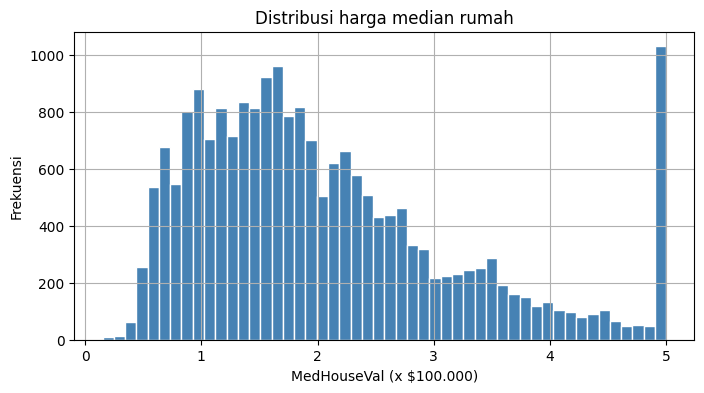

In [ ]:
# Eksplorasi Tambahan: distribusi variabel target
plt.figure(figsize=(8, 4))
housing_df['MedHouseVal'].hist(bins=50, color='steelblue', edgecolor='white')
plt.xlabel('MedHouseVal (x $100.000)')
plt.ylabel('Frekuensi')
plt.title('Distribusi harga median rumah')
plt.show()

Penjelasan:
Histogram target tidak berbentuk lonceng simetris, melainkan miring ke kanan, dengan lonjakan tajam di nilai sekitar 5.0

## **2.2. Feature Correlation Calculation**

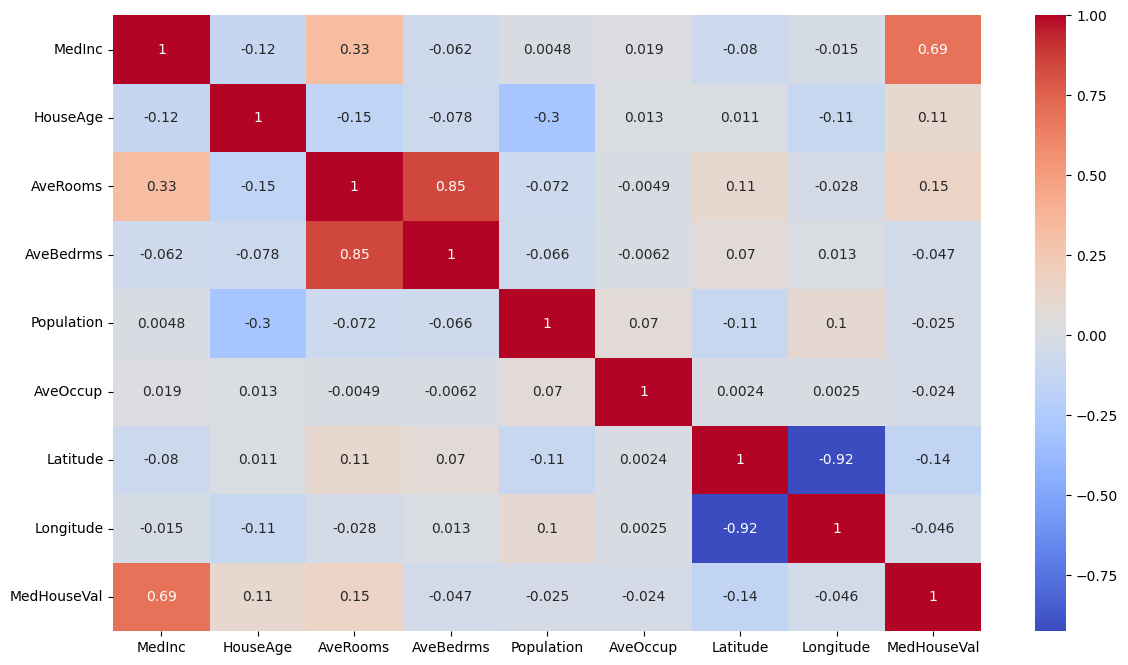

In [104]:
# Melakukan perhitungan feature correlation
plt.figure(figsize=(14, 8))
corr = housing_df.corr()
heatmap = sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2g")

Penjelasan:
Matriks korelasi menunjukkan hubungan antarfitur dalam dataset, dengan nilai 1 pada diagonal dan pola yang simetris. Korelasi dengan `MedHouseVal` paling kuat terdapat pada `MedInc`, yaitu sekitar 0,69, yang menunjukkan hubungan positif cukup kuat. Selain itu, `Latitude` dan `Longitude` memiliki korelasi negatif yang sangat kuat karena keduanya sama-sama merepresentasikan lokasi geografis yang memiliki pola informasi yang saling berkaitan.

In [105]:
# Negative correlation yang kuat, sama bergunanya dengan positive correlation
# yang kuat. Sehingga perlu dilakukan sort terhadap nilai absotule-nya
abs(corr['MedHouseVal']).sort_values(ascending=False)

,MedHouseVal
MedHouseVal,1.000000
MedInc,0.688075
AveRooms,0.151948
Latitude,0.144160
HouseAge,0.105623
AveBedrms,0.046701
Longitude,0.045967
Population,0.024650
AveOccup,0.023737


Penjelasan:
MedInc, AveRooms, Latitude, dan HouseAge memiliki korelasi terbesar dengan MedHouseVal

## **2.3. Data Preparation**

In [106]:
# y merupakan variable dependent, target variable (yang akan diestimasi oleh model kita)
y = housing_df['MedHouseVal']

# X merupakan features yang akan diberikan kepada model. loc digunakan untuk
# melakukan slice pada DataFrame, dan diambil feature dengan corr yang baik dengan target
X = housing_df.loc[:, ['MedInc', 'AveRooms', 'Latitude', 'HouseAge']]

# Menampilkan ukuran dari setiap variabel X dan y
print(f"Data X = {X.shape}")
print(f"Data y = {y.shape}")

Data X = (20640, 4)
Data y = (20640,)


Penjelasan:
y digunakan sebagai target yang ingin diprediksi, yaitu MedHouseVal, sedangkan X berisi empat fitur yang dipilih sebagai input model, yaitu MedInc, AveRooms, Latitude, dan HouseAge.

In [107]:
# Melakukan normalisasi data ke dalam rentang nilai data yang seragam
min_max_scaler = preprocessing.MinMaxScaler()
X = min_max_scaler.fit_transform(X.values.reshape(-1, X.shape[1]))
y = min_max_scaler.fit_transform(y.values.reshape(-1, 1))

X = pd.DataFrame(X)
y = pd.DataFrame(y)

print(f"Contoh data X setelah normalisasi \n{X.head()}\n")
print(f"Contoh data y setelah normalisasi \n{y.head()}")

Contoh data X setelah normalisasi 
          0         1         2         3
0  0.539668  0.043512  0.567481  0.784314
1  0.538027  0.038224  0.565356  0.392157
2  0.466028  0.052756  0.564293  1.000000
3  0.354699  0.035241  0.564293  1.000000
4  0.230776  0.038534  0.564293  1.000000

Contoh data y setelah normalisasi 
          0
0  0.902266
1  0.708247
2  0.695051
3  0.672783
4  0.674638


Normalisasi Min-Max mengubah nilai setiap fitur ke rentang 0 sampai 1 agar perbedaan skala tidak mengganggu proses gradient descent.

In [108]:
# Eksplorasi Tambahan: memastikan semua kolom X dan y berada pada rentang [0, 1]
print("Min tiap kolom X :", X.min().round(3).tolist())
print("Max tiap kolom X :", X.max().round(3).tolist())
print("Min / Max y      :", float(y.min().iloc[0]), "/", float(y.max().iloc[0]))
print()
print("Rata-rata tiap kolom X (0=MedInc, 1=AveRooms, 2=Latitude, 3=HouseAge):")
print(X.mean().round(3).to_string())

Min tiap kolom X : [0.0, 0.0, 0.0, 0.0]
Max tiap kolom X : [1.0, 1.0, 1.0, 1.0]
Min / Max y      : 0.0 / 1.0

Rata-rata tiap kolom X (0=MedInc, 1=AveRooms, 2=Latitude, 3=HouseAge):
0    0.232
1    0.032
2    0.329
3    0.542


Penjelasan:
Hasil normalisasi menunjukkan bahwa semua kolom memiliki nilai minimum 0 dan maksimum 1, sehingga proses normalisasi berjalan sesuai harapan. Namun, rata-rata kolom AveRooms sangat rendah karena sebagian besar nilainya terkumpul dekat 0 akibat adanya outlier ekstrem pada fitur tersebut.

In [109]:
# Proses pembagian kumpulan data ke dalam data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")

X_train: (14448, 4), X_test: (6192, 4)
y_train: (14448, 1), y_test: (6192, 1)


Penjelasan:
Membagi data train dan data test dengan rasio 7 : 3

## **2.4. Model Definition**

In [110]:
# Pembentukan class dari arsitektur model sebagai tujuan proses training
class LinearRegressor(torch.nn.Module):
    def __init__(self, n_features, n_outputs):
        super().__init__()
        self.net = torch.nn.Linear(n_features, n_outputs)

    def forward(self, x):
        return self.net(x)

# Beberapa catatan penting:
# 1. super().__init__() digunakan sebagai metode untuk melakukan inisialisasi variabel dari parent class
# 2. n_feature berisi jumlah total variabel dari feature
# 3. n_output berisi jumlah variable target yang harus diestimasi
# 4. Kita akan mengubah penggunaan y = linreg(data) menjadi y = LinearRegressor.forward(data)

Penjelasan:
Mendefinisikan model ANN untuk melakukan regresi linear

In [111]:
# Penggunaan arsitektur yang akan dilakukan pelatihan dan pengujian
n_features = X.shape[1]  # 4
n_outputs = 1

model = LinearRegressor(n_features, n_outputs)
print(model)

# Menampilkan nama dan nilai dari semua trainable parameter
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name, param.data)

LinearRegressor(
  (net): Linear(in_features=4, out_features=1, bias=True)
)
net.weight tensor([[ 0.3823,  0.4150, -0.1171,  0.4593]])
net.bias tensor([-0.1096])


Model memiliki 4 fitur input dan 1 output karena hanya memprediksi MedHouseVal.

In [112]:
# Eksplorasi Tambahan: menghitung jumlah parameter dan memverifikasi bahwa
# model(x) sama dengan perhitungan manual x @ W^T + b
total_params = sum(p.numel() for p in model.parameters())
print("Total parameter yang dapat dilatih:", total_params)

sample = torch.tensor(X_train.values[:3], dtype=torch.float32)
hasil_model = model(sample)
hasil_manual = sample @ model.net.weight.T + model.net.bias

print("\nOutput model(x) :", hasil_model.detach().numpy().flatten())
print("Perhitungan manual:", hasil_manual.detach().numpy().flatten())
print("Sama?", torch.allclose(hasil_model, hasil_manual))

Total parameter yang dapat dilatih: 5

Output model(x) : [0.34223276 0.25832075 0.18743888]
Perhitungan manual: [0.34223276 0.25832075 0.18743888]
Sama? True


Model memiliki total 5 parameter yang dapat dilatih, yaitu 4 weight dan 1 bias. Hasil perhitungan model(x) juga sama dengan perhitungan matriks manual, sehingga dapat dipastikan bahwa model tersebut pada dasarnya adalah regresi linier berganda yang diimplementasikan menggunakan PyTorch.

## **2.5. Training Process**

In [113]:
# Inisialisasi beberapa parameter dan fungsi untuk mendukung proses training
lr = 0.001
num_epochs = 100
batch_size = 256

optimizer = torch.optim.SGD(model.parameters(), lr)
loss_function = torch.nn.MSELoss()

Hyperparameter yang digunakan terdiri dari lr=0.001 sebagai learning rate, num_epochs=100 sebagai jumlah putaran training, dan batch_size=256 sebagai jumlah sampel dalam setiap mini-batch. Model menggunakan optimizer SGD untuk memperbarui parameter dan MSELoss sebagai fungsi loss yang mengukur rata-rata kuadrat selisih antara prediksi dan nilai sebenarnya. Kombinasi ini digunakan untuk melatih model regresi secara bertahap agar nilai loss semakin kecil.

In [114]:
# Konversi DataFrame ke dalam torch tensors
training_set = torch.utils.data.TensorDataset(
    torch.tensor(X_train.values, dtype=torch.float32),
    torch.tensor(y_train.values, dtype=torch.float32))

test_set = torch.utils.data.TensorDataset(
    torch.tensor(X_test.values, dtype=torch.float32),
    torch.tensor(y_test.values, dtype=torch.float32))

# Pembuatan DataLoader untuk kedua kumpulan data, yang melibatkan
# sampling batches khususnya untuk data training
training_loader = torch.utils.data.DataLoader(training_set, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_set, shuffle=False)

PyTorch menggunakan tensor, sehingga data dari DataFrame diubah menjadi tensor float32, lalu TensorDataset menggabungkan fitur dan target menjadi pasangan data.

In [115]:
# Eksplorasi Tambahan: memeriksa isi DataLoader
print("Jumlah batch per epoch (training):", len(training_loader))
xb, yb = next(iter(training_loader))
print("Bentuk satu batch -> X:", xb.shape, "| y:", yb.shape)

Jumlah batch per epoch (training): 57
Bentuk satu batch -> X: torch.Size([256, 4]) | y: torch.Size([256, 1])


Terdapat 57 batch pada setiap epoch, sehingga selama 100 epoch terjadi sekitar 5.700 kali pembaruan parameter.

In [116]:
# Mengatur mode training untuk model
model.train()

loss_train = []
for epoch in range(num_epochs):
    loss_batch = []
    for input, target in training_loader:
        # Optimizer gradient diatur menjadi zero, sehingga dapat dihitung ulang untuk langkah pelatihan tertentu
        optimizer.zero_grad()

        # Model memberikan luaran regresi
        output = model(input)

        # Perhitungan loss function
        loss = loss_function(output, target)
        loss_batch.append(loss.detach().cpu())

        # Menghitung gradien loss sehubungan dengan setiap parameter model yang akan diperbarui.
        # Ini dikenal sebagai backpropagation
        loss.backward()

        # Memperbaharui parameter sehubungan dengan gradien loss untuk memperbaikinya
        optimizer.step()

    loss_train.append(np.mean(loss_batch))
    print(f"[Epoch {epoch + 1}] - Training loss: {loss_train[-1]}")

[Epoch 1] - Training loss: 0.07897624373435974
[Epoch 2] - Training loss: 0.070411816239357
[Epoch 3] - Training loss: 0.06413479149341583
[Epoch 4] - Training loss: 0.0596175342798233
[Epoch 5] - Training loss: 0.05635571852326393
[Epoch 6] - Training loss: 0.05400700494647026
[Epoch 7] - Training loss: 0.052183110266923904
[Epoch 8] - Training loss: 0.05105341225862503
[Epoch 9] - Training loss: 0.049974728375673294
[Epoch 10] - Training loss: 0.04940526559948921
[Epoch 11] - Training loss: 0.04860394448041916
[Epoch 12] - Training loss: 0.048288438469171524
[Epoch 13] - Training loss: 0.04796008765697479
[Epoch 14] - Training loss: 0.04755023494362831
[Epoch 15] - Training loss: 0.047375861555337906
[Epoch 16] - Training loss: 0.047116756439208984
[Epoch 17] - Training loss: 0.04686468839645386
[Epoch 18] - Training loss: 0.04663173854351044
[Epoch 19] - Training loss: 0.046487193554639816
[Epoch 20] - Training loss: 0.046358995139598846
[Epoch 21] - Training loss: 0.046062428504228

Training loop menjalankan proses pembelajaran untuk setiap mini-batch selama 100 epoch. Pada setiap batch, gradien lama dihapus dengan optimizer.zero_grad(), model melakukan forward pass untuk menghasilkan prediksi, lalu MSELoss menghitung kesalahan. Selanjutnya, loss.backward() menghitung gradien melalui backpropagation, dan optimizer.step() memperbarui weight serta bias menggunakan SGD. Loss setiap batch kemudian dirata-ratakan untuk mencatat perkembangan training pada setiap epoch.

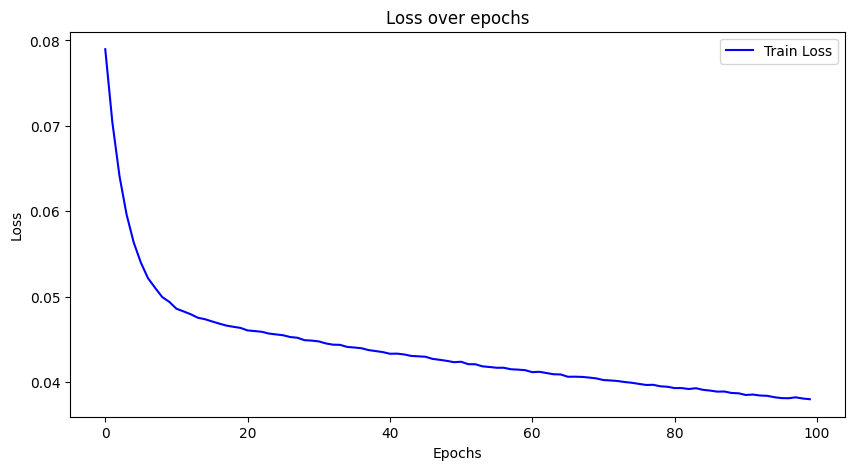

In [117]:
# Melakukan plot kualitas model (loss) vs training epochs
plt.figure(figsize=(10, 5))
plt.plot(loss_train, '-', color='blue', label='Train Loss')
plt.title('Loss over epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

Kurva ini merupakan learning curve yang menunjukkan perubahan training loss terhadap jumlah epoch. Loss yang menurun menunjukkan model terus belajar, sedangkan kurva yang mulai mendatar menunjukkan laju perbaikannya semakin kecil. Dengan learning rate 0.001, loss turun cukup cepat di awal lalu melandai, tetapi kondisi ini belum tentu berarti model sudah benar-benar konvergen. Kemungkinan model masih dapat mengalami perbaikan jika training dilanjutkan karena learning rate yang kecil membuat pembaruan parameter berlangsung lebih lambat.

### **Eksplorasi Tambahan: Pengaruh Learning Rate dan Perbandingan dengan Solusi Analitik**

Solusi analitik  -> MSE train: 0.02674 | MSE test: 0.02850 | R2 test: 0.4972
lr = 0.001  -> loss train akhir: 0.03802 | MSE test: 0.03815 | R2 test: 0.3269
lr = 0.01   -> loss train akhir: 0.02756 | MSE test: 0.02844 | R2 test: 0.4981
lr = 0.1    -> loss train akhir: 0.02715 | MSE test: 0.02831 | R2 test: 0.5006


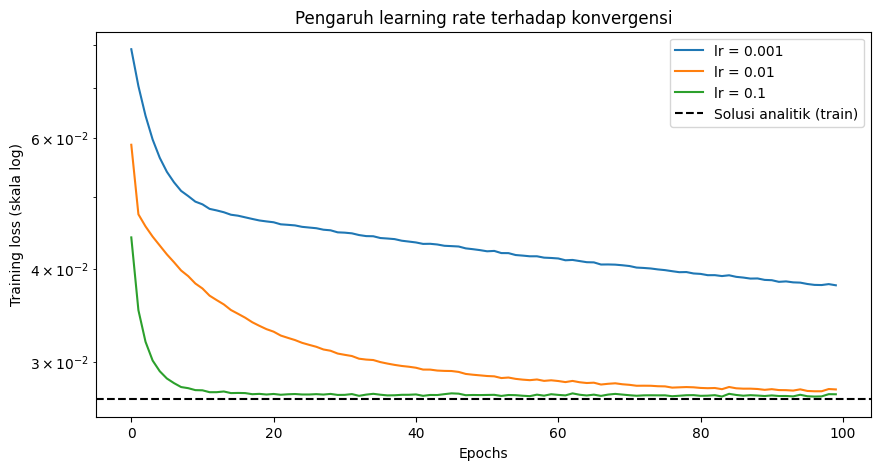

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Solusi analitik sebagai acuan (batas terbaik untuk model linier ini)
lin = LinearRegression().fit(X_train, y_train)
mse_train_ref = mean_squared_error(y_train, lin.predict(X_train))
mse_test_ref = mean_squared_error(y_test, lin.predict(X_test))
r2_test_ref = r2_score(y_test, lin.predict(X_test))
print(f"Solusi analitik  -> MSE train: {mse_train_ref:.5f} | MSE test: {mse_test_ref:.5f} | R2 test: {r2_test_ref:.4f}")

# 2. Fungsi untuk melatih model baru dengan learning rate tertentu
def train_linear_model(lr, num_epochs=100, batch_size=256, seed=42):
    torch.manual_seed(seed)
    m = LinearRegressor(n_features, n_outputs)
    opt = torch.optim.SGD(m.parameters(), lr)
    loader = torch.utils.data.DataLoader(training_set, batch_size=batch_size, shuffle=True)
    history = []
    for epoch in range(num_epochs):
        batch_losses = []
        for xb, yb in loader:
            opt.zero_grad()
            loss = loss_function(m(xb), yb)
            loss.backward()
            opt.step()
            batch_losses.append(loss.item())
        history.append(np.mean(batch_losses))
    return m, history

X_test_t = torch.tensor(X_test.values, dtype=torch.float32)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32)

plt.figure(figsize=(10, 5))
for lr_try in [0.001, 0.01, 0.1]:
    m, hist = train_linear_model(lr_try)
    with torch.no_grad():
        mse_t = loss_function(m(X_test_t), y_test_t).item()
    r2_t = 1 - mse_t / float(np.var(y_test.values))
    print(f"lr = {lr_try:<6} -> loss train akhir: {hist[-1]:.5f} | MSE test: {mse_t:.5f} | R2 test: {r2_t:.4f}")
    plt.plot(hist, label=f'lr = {lr_try}')

plt.axhline(mse_train_ref, color='black', linestyle='--', label='Solusi analitik (train)')
plt.yscale('log')
plt.xlabel('Epochs')
plt.ylabel('Training loss (skala log)')
plt.title('Pengaruh learning rate terhadap konvergensi')
plt.legend()
plt.show()

Garis putus-putus menunjukkan loss minimum yang dapat dicapai model linier pada data latih. Dengan learning rate 0.001, loss masih berada di atas nilai optimum setelah 100 epoch, sehingga model belum sepenuhnya konvergen. Sementara itu, learning rate 0.01 dan 0.1 membuat loss turun lebih cepat dan mendekati nilai optimum. Hal ini menunjukkan bahwa pemilihan learning rate sangat berpengaruh terhadap kecepatan training.

## **2.6. Testing Process**

In [ ]:
# Mengatur mode testing untuk model
model.eval()

test_losses = []
for input, target in test_loader:
    # Melakukan non aktif dari gradient computation
    with torch.no_grad():
        output = model(input)  # model.forward(input)
        loss = loss_function(output, target)
        test_losses += [loss.item()]

print(f"Mean test loss = {np.mean(test_losses)}")
print(f"Nilai dari bobot(w): \n{model.net.weight}\n")
print(f"Nilai dari bias(b): \n{model.net.bias}")

Mean test loss = 0.03815307182401093
Nilai dari bobot(w): 
Parameter containing:
tensor([[ 0.5866,  0.4260, -0.0882,  0.3570]], requires_grad=True)

Nilai dari bias(b): 
Parameter containing:
tensor([0.0775], requires_grad=True)


Pada tahap testing, model.eval() mengubah model ke mode evaluasi, sedangkan torch.no_grad() menonaktifkan perhitungan gradien agar proses lebih ringan. Model kemudian menghasilkan prediksi untuk setiap data uji dan menghitung loss, yang dirata-ratakan menjadi Mean Test Loss atau MSE. Karena test_loader menggunakan batch_size=1, rata-rata loss tersebut setara dengan MSE seluruh data uji.

### **Prediksi Harga Rumah**

In [ ]:
# Eksplorasi Tambahan: menampilkan persamaan hasil training dengan nilai bobot yang sebenarnya
nama_fitur = ['MedInc', 'AveRooms', 'Latitude', 'HouseAge']
w = model.net.weight.detach().numpy().flatten()
b = model.net.bias.item()

persamaan = " + ".join(f"({wi:.4f} * {nm})" for wi, nm in zip(w, nama_fitur))
print(f"MedHouseVal = {persamaan} + ({b:.4f})")

print("\nBobot per fitur:")
for nm, wi in zip(nama_fitur, w):
    print(f"  {nm:<10}: {wi:+.4f}")
print(f"  {'bias':<10}: {b:+.4f}")

MedHouseVal = (0.5866 * MedInc) + (0.4260 * AveRooms) + (-0.0882 * Latitude) + (0.3570 * HouseAge) + (0.0775)

Bobot per fitur:
  MedInc    : +0.5866
  AveRooms  : +0.4260
  Latitude  : -0.0882
  HouseAge  : +0.3570
  bias      : +0.0775


Sel ini menyusun persamaan regresi berdasarkan bobot hasil training. Besarnya bobot menunjukkan pengaruh setiap fitur terhadap prediksi pada skala ternormalisasi. MedInc diperkirakan memiliki pengaruh positif paling besar, sedangkan Latitude cenderung memiliki pengaruh negatif.

In [ ]:
all_predicted_values = []

# Membuat prediksi menggunakan model yang telah dilatih dan menyimpan hasilnya
with torch.no_grad():
    for input_data, _ in test_loader:
        predicted_values_batch = model(input_data)
        all_predicted_values.append(predicted_values_batch.cpu().numpy())

predicted_values = np.concatenate(all_predicted_values, axis=0).reshape(-1, 1)

# Melakukan scatter plot dari actual vs predicted values
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test.values.flatten(), y=predicted_values.flatten())
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Linear Regression - Actual vs Predicted Values')
plt.show()

AttributeError: 'numpy.ndarray' object has no attribute 'values'

<Figure size 800x600 with 0 Axes>

Prediksi pada 6.192 data uji digabungkan dan dibandingkan dengan nilai aktual dalam urutan yang sama karena shuffle=False. Plot menunjukkan model mampu menangkap tren umum, tetapi sebaran prediksi masih cukup lebar. Titik pada nilai aktual 1.0 muncul karena target dipotong pada 5.0, sementara prediksi cenderung berada di sekitar nilai tengah karena keterbatasan model linier.

In [ ]:
# Eksplorasi Tambahan: evaluasi kuantitatif dan plot dengan garis ideal y = x
y_true = y_test.values.flatten()
y_pred = predicted_values.flatten()

mse_final = mean_squared_error(y_true, y_pred)
r2_final = r2_score(y_true, y_pred)

# Mengembalikan galat ke satuan dolar. Rentang target asli = max - min (dalam satuan $100.000)
rentang_target = housing['target'].max() - housing['target'].min()
rmse_usd = np.sqrt(mse_final) * rentang_target * 100000

print(f"MSE (ternormalisasi) : {mse_final:.5f}")
print(f"R2 pada data uji     : {r2_final:.4f}")
print(f"RMSE dalam dolar     : sekitar ${rmse_usd:,.0f}")
print(f"Acuan solusi analitik -> MSE: {mse_test_ref:.5f} | R2: {r2_test_ref:.4f}")

MSE (ternormalisasi) : 0.03815
R2 pada data uji     : 0.3269
RMSE dalam dolar     : sekitar $94,735
Acuan solusi analitik -> MSE: 0.02850 | R2: 0.4972


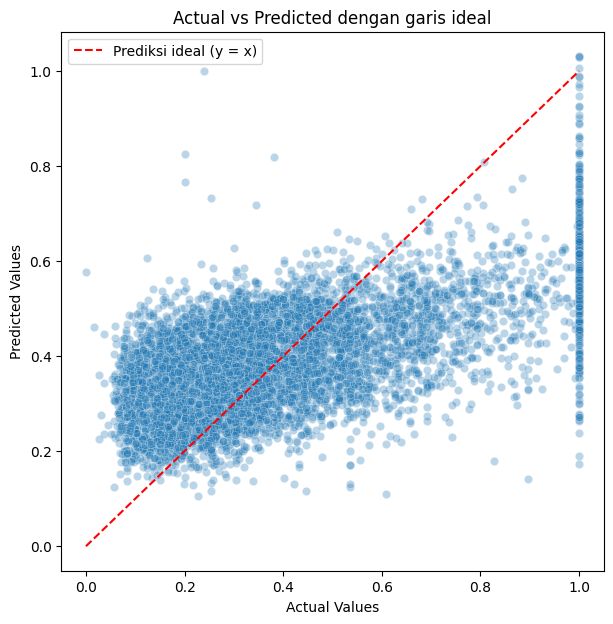

In [ ]:
plt.figure(figsize=(7, 7))
sns.scatterplot(x=y_true, y=y_pred, alpha=0.3)
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Prediksi ideal (y = x)')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted dengan garis ideal')
plt.legend()
plt.show()

Nilai R² menunjukkan seberapa besar variasi harga rumah yang dapat dijelaskan model, sedangkan RMSE dalam dolar menunjukkan rata-rata besar kesalahan prediksi dalam satuan harga asli. Dibandingkan dengan solusi analitik, hasil training masih memiliki selisih karena model belum sepenuhnya konvergen.

# **3. Kesimpulan**

LSE menghasilkan parameter yang hampir sama dengan fungsi asli dan menunjukkan hasil yang konsisten tanpa overfitting.

Pada California Housing, eksplorasi data membantu menemukan perbedaan skala, outlier, dan target yang terpotong, sehingga normalisasi dan pemilihan fitur diperlukan. Model nn.Linear setara dengan regresi linier berganda, tetapi performanya dipengaruhi oleh learning rate dan proses konvergensi.

Hasil Actual vs Predicted juga menunjukkan keterbatasan model linier dalam menangkap hubungan yang kompleks, sehingga peningkatan fitur atau penggunaan model nonlinier dapat dipertimbangkan.